# Flow matching, built forward

Diffusion's simpler cousin, and the repo's policy for T2 (two bins, the expert flips a coin).

### step 0 — the problem: one observation, two right answers

In [1]:
import torch

# T2 in one number: the same observation every time, and the expert puts the cube
# in the left bin (-1) half the time and the right bin (+1) the other half
torch.manual_seed(0)
y = torch.where(torch.rand(1000) < 0.5, -1.0, 1.0)  # [1000], which bin each demo used
print(f"demos: left {(y < 0).sum().item()}  right {(y > 0).sum().item()}")
print(f"best single answer under MSE = the mean: {y.mean():+.3f}   <- between the bins")

demos: left 492  right 508
best single answer under MSE = the mean: +0.016   <- between the bins


### step 1 — a regression net on it: one answer, every time

In [2]:
from torch import nn

obs = torch.zeros(1000, 1)  # [1000, 1], the same observation for every demo
for name, loss_fn in [("MSE", lambda p: ((p - y[:, None]) ** 2).mean()),
                      ("L1 ", lambda p: (p - y[:, None]).abs().mean())]:
    torch.manual_seed(0)
    net = nn.Sequential(nn.Linear(1, 64), nn.ReLU(), nn.Linear(64, 1))  # obs -> one action
    opt = torch.optim.AdamW(net.parameters(), lr=1e-2)
    for step in range(500):
        loss = loss_fn(net(obs))
        opt.zero_grad()
        loss.backward()
        opt.step()
    print(f"{name}: the net always answers {net(obs[:1]).item():+.3f}")

MSE: the net always answers +0.016
L1 : the net always answers +0.996


### step 2 — the training paths: noise → demo, in a straight line

Pair a random noise value `x0` with a demo `x1` and join them: `x_t = (1 − t)·x0 + t·x1`.
Its speed along the way is constant: `d x_t / dt = x1 − x0`. That speed is what the net will learn to predict.

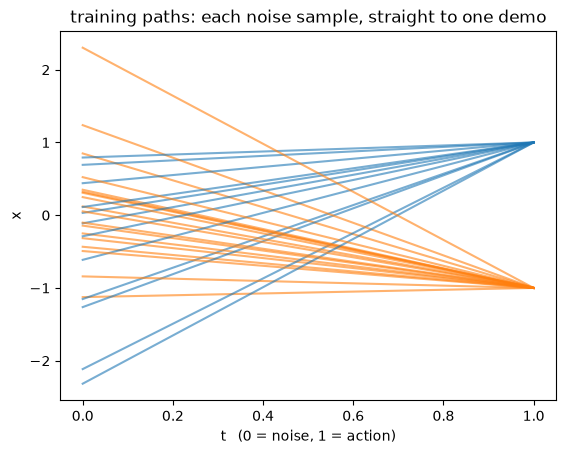

In [3]:
import matplotlib.pyplot as plt

torch.manual_seed(0)
x0 = torch.randn(30)  # [30], noise: where each answer starts
x1 = y[:30]  # [30], a demo for each: where it should end, -1 or +1

# the straight line from noise to demo, x_t = (1 - t) * x0 + t * x1, for t from 0 to 1
t = torch.linspace(0, 1, 2)  # [2], the two ends are enough for a straight line
for a, b in zip(x0, x1):
    plt.plot(t, (1 - t) * a + t * b, color="tab:blue" if b > 0 else "tab:orange", alpha=0.6)
plt.xlabel("t   (0 = noise, 1 = action)")
plt.ylabel("x")
plt.title("training paths: each noise sample, straight to one demo")
plt.show()

### step 3 — train the speed net: input (x, t), target `x1 − x0`

In [4]:
torch.manual_seed(0)
# (where you are, when) -> how fast to move; SiLU, a smooth ReLU, since the speeds should vary smoothly
vnet = nn.Sequential(nn.Linear(2, 128), nn.SiLU(), nn.Linear(128, 128), nn.SiLU(), nn.Linear(128, 1))
opt = torch.optim.AdamW(vnet.parameters(), lr=1e-3)
for step in range(3001):
    i = torch.randint(0, len(y), (256,))  # [256], a batch of demos
    x1 = y[i]  # [256], where each path ends
    x0 = torch.randn(256)  # [256], fresh noise: where each path starts
    t = torch.rand(256)  # [256], a random point along each path
    xt = (1 - t) * x0 + t * x1  # [256], the point at time t
    pred = vnet(torch.stack([xt, t], dim=-1))[:, 0]  # [256], predicted speed
    # MSE on purpose: where paths cross, the AVERAGE speed is the right answer (step 2)
    loss = ((pred - (x1 - x0)) ** 2).mean()
    opt.zero_grad()
    loss.backward()
    opt.step()
    if step % 1000 == 0:
        print(f"{step:5d}  loss {loss.item():.3f}")

    0  loss 2.082
 1000  loss 1.301
 2000  loss 0.951
 3000  loss 1.025


### step 4 — sample: start from noise, follow the speeds, see where it ends

left 471   middle 31   right 498


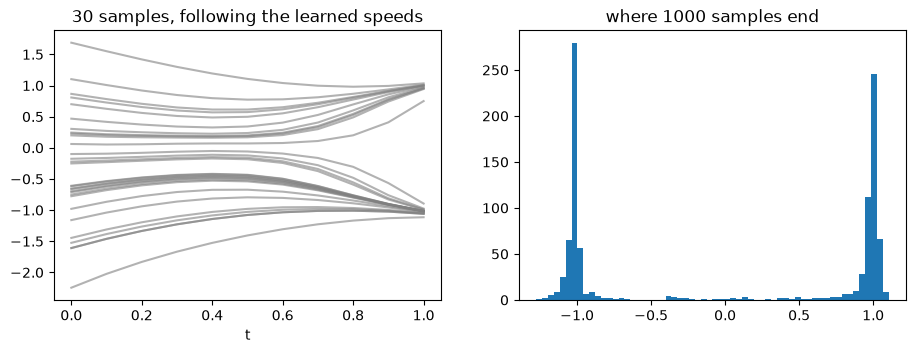

In [6]:
from torch import Tensor


@torch.no_grad()
def sample(n: int, steps: int = 10) -> Tensor:
    # out: [steps + 1, n], every sample's position at each time, t = 0 .. 1
    x = torch.randn(n)  # [n], start: fresh noise
    path = [x]
    for k in range(steps):  # Euler: move at the predicted speed for dt, repeat
        t = torch.full((n,), k / steps)  # [n]
        x = x + vnet(torch.stack([x, t], dim=-1))[:, 0] / steps  # [n], x += speed * dt
        path.append(x)
    return torch.stack(path)


torch.manual_seed(1)
path = sample(1000)  # [11, 1000]
end = path[-1]  # [1000], the sampled answers
print(f"left {(end < -0.5).sum().item()}   middle {(end.abs() <= 0.5).sum().item()}   right {(end > 0.5).sum().item()}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(torch.linspace(0, 1, 11), path[:, :30], color="grey", alpha=0.6)  # 30 of them over time
ax[0].set_xlabel("t")
ax[0].set_title("30 samples, following the learned speeds")
ax[1].hist(end, bins=60)
ax[1].set_title("where 1000 samples end")
plt.show()

### step 5 — the speed net also sees the scene

In [7]:
torch.manual_seed(0)
# the scene now matters: obs -1 -> always left, +1 -> always right, 0 -> coin flip
obs_c = torch.randint(-1, 2, (3000,)).float()  # [3000], one observation per demo
coin = torch.where(torch.rand(3000) < 0.5, -1.0, 1.0)  # [3000]
y_c = torch.where(obs_c == 0, coin, obs_c)  # [3000], the bin each demo used

# step 3's speed net with one more input: what the scene looks like
cnet = nn.Sequential(nn.Linear(3, 128), nn.SiLU(), nn.Linear(128, 128), nn.SiLU(), nn.Linear(128, 1))
opt = torch.optim.AdamW(cnet.parameters(), lr=1e-3)
for step in range(3001):
    i = torch.randint(0, len(y_c), (256,))  # [256]
    x1, x0, t = y_c[i], torch.randn(256), torch.rand(256)  # [256] each
    xt = (1 - t) * x0 + t * x1  # [256]
    pred = cnet(torch.stack([xt, t, obs_c[i]], dim=-1))[:, 0]  # [256], speed given (x, t, obs)
    loss = ((pred - (x1 - x0)) ** 2).mean()
    opt.zero_grad()
    loss.backward()
    opt.step()
    if step % 1000 == 0:
        print(f"{step:5d}  loss {loss.item():.3f}")

    0  loss 1.905
 1000  loss 0.372
 2000  loss 0.470
 3000  loss 0.473


### step 6 — sample 1000 answers for each scene

In [8]:
@torch.no_grad()
def sample_c(obs: float, n: int = 1000, steps: int = 10) -> Tensor:
    # step 4's sampler, with the observation held fixed
    # out: [n], the sampled answers
    x = torch.randn(n)  # [n]
    o = torch.full((n,), obs)  # [n]
    for k in range(steps):
        t = torch.full((n,), k / steps)  # [n]
        x = x + cnet(torch.stack([x, t, o], dim=-1))[:, 0] / steps
    return x


torch.manual_seed(1)
for obs in [-1.0, 0.0, 1.0]:
    end = sample_c(obs)
    print(f"obs {obs:+.0f}:  left {(end < -0.5).sum().item():4d}   "
          f"middle {(end.abs() <= 0.5).sum().item():3d}   right {(end > 0.5).sum().item():4d}")

obs -1:  left 1000   middle   0   right    0
obs +0:  left  510   middle  56   right  434
obs +1:  left    0   middle   2   right  998


## The robot: T2-fixed

Two mirrored bins, the cube always at the table centre, and the expert flips a coin for the bin each demo. 100 demos with half shake.

### step 7 — the data

In [10]:
import json
from pathlib import Path

import numpy as np
from lerobot.datasets.lerobot_dataset import LeRobotDataset

np.set_printoptions(precision=3, suppress=True)
REPO = Path.cwd().parent
ROOT = REPO / "data/robosuite/pick_place_two_bins_fixed_noise0025_n100"
ds = LeRobotDataset("dream_robot/pick_place_two_bins", root=ROOT)
print(f"{ds.num_episodes} demos  {ds.num_frames} frames")

# T2-fixed: the cube always starts at the table centre, so the scene never says which bin.
# The expert's coin isn't in the dataset; record.py logged it per recording attempt
attempts = [a for a in json.load(open(ROOT / "bin_choices.json"))["attempts"] if a["kept"]]
bin_of = np.array([a["target_bin"] for a in attempts])  # [100], episode e = the e-th kept attempt
print(f"left {(bin_of == 'left').sum()}  right {(bin_of == 'right').sum()}")

state = np.asarray(ds.hf_dataset["observation.state"], dtype=np.float32)  # [N, 8]
action = np.asarray(ds.hf_dataset["action"], dtype=np.float32)  # [N, 8]
episode = np.asarray(ds.hf_dataset["episode_index"])  # [N]
rng = np.random.default_rng(0)
# hold out 10 whole demos, 5 per bin: a plain random 10 came out 9 right / 1 left
val_eps = np.concatenate([rng.choice(np.flatnonzero(bin_of == b), 5, replace=False) for b in ["left", "right"]])
is_val = np.isin(episode, val_eps)  # [N]
print(f"{state.shape=}  train {(~is_val).sum()}  val {is_val.sum()}  {val_eps=}")

100 demos  21741 frames
left 50  right 50
state.shape=(21741, 8)  train 19555  val 2186  val_eps=array([59, 49, 27, 31, 79, 74, 48, 60, 87, 99])


### step 8 — both cameras into RAM (~1 min)

In [11]:
import torch

# both cameras, decoded once, as uint8 (~2.1 GB); step 9 moves them to the GPU
cams = ["top", "wrist"]
N = len(ds)
ims = {cam: np.zeros((N, 3, 128, 128), dtype=np.uint8) for cam in cams}  # {cam: [N, 3, H, W]}
for i in range(N):
    item = ds[i]
    for cam in cams:
        ims[cam][i] = (item[f"observation.images.{cam}"] * 255).round().to(torch.uint8).numpy()
print({cam: im.shape for cam, im in ims.items()}, f"{sum(im.nbytes for im in ims.values()) / 1e9:.1f} GB")

{'top': (21741, 3, 128, 128), 'wrist': (21741, 3, 128, 128)} 2.1 GB


### step 9 — chunk targets (K = 16), everything to the GPU, normalisation stats

In [12]:
from torch import Tensor, nn

K = 16  # chunk length, the repo's flow-matching value: 16 steps = 0.5 s (ACT used 50)

# chunk targets, as act.ipynb step 1: the next K actions, padded at the demo's end
assert (np.diff(episode) >= 0).all(), "demos not stored in order"
last = np.searchsorted(episode, episode, side="right") - 1  # [N], last row of each frame's demo
idx = np.arange(N)[:, None] + np.arange(K)  # [N, K]
pad = idx > last[:, None]  # [N, K], True past the demo's end
chunks = action[np.minimum(idx, last[:, None])]  # [N, K, 8]

dev = "cuda"
tr, va = ~is_val, is_val
IM = {cam: (torch.tensor(ims[cam][tr]).to(dev), torch.tensor(ims[cam][va]).to(dev)) for cam in cams}
Xtr, Xva = torch.tensor(state[tr]).to(dev), torch.tensor(state[va]).to(dev)  # [Ntr | Nva, 8]
Ctr, Cva = torch.tensor(chunks[tr]).to(dev), torch.tensor(chunks[va]).to(dev)  # [Ntr | Nva, K, 8]
Ptr, Pva = torch.tensor(pad[tr]).to(dev), torch.tensor(pad[va]).to(dev)  # [Ntr | Nva, K]

# normalisation stats from train only, as bc_2 / act
s_mean, s_std = Xtr.mean(0), Xtr.std(0)  # [8] each
a_mean, a_std = Ctr[:, 0].mean(0), Ctr[:, 0].std(0)  # [8] each
im_stats = {}  # {cam: (mean, std)}, each [1, 3, 1, 1]
for cam in cams:
    sub = IM[cam][0][::20].float() / 255
    im_stats[cam] = (sub.mean(dim=(0, 2, 3)).reshape(1, 3, 1, 1), sub.std(dim=(0, 2, 3)).reshape(1, 3, 1, 1))
print(f"{Ctr.shape=}  {Cva.shape=}  GPU {torch.cuda.memory_allocated() / 1e9:.1f} GB")

Ctr.shape=torch.Size([19555, 16, 8])  Cva.shape=torch.Size([2186, 16, 8])  GPU 2.3 GB


### step 10 — BC's image encoder, as before

In [13]:
# BC's image encoder, as bc_2 steps 9 and 15 (and act step 5)
def make_conv() -> nn.Sequential:
    return nn.Sequential(
        nn.Conv2d(3, 32, 5, 2, 2),  # -> [B, 32, 64, 64]
        nn.ReLU(),
        nn.Conv2d(32, 64, 3, 2, 1),  # -> [B, 64, 32, 32]
        nn.ReLU(),
        nn.Conv2d(64, 128, 3, 2, 1),  # -> [B, 128, 16, 16]
        nn.ReLU(),
        nn.Conv2d(128, 64, 3, 1, 1),  # -> [B, 64, 16, 16], no ReLU: the softmax wants negatives
    )


class SpatialSoftmax(nn.Module):
    def __init__(self, h: int, w: int):
        super().__init__()
        self.log_t = nn.Parameter(torch.zeros(()))  # learned temperature, T = exp(log_t) > 0
        self.register_buffer("cell_x", torch.linspace(-1, 1, w).repeat(h))  # [H*W]
        self.register_buffer("cell_y", torch.linspace(-1, 1, h).repeat_interleave(w))  # [H*W]

    def forward(self, f: Tensor) -> Tensor:
        # f: [B, C, H, W] feature maps
        # out: [B, 2C], an (x, y) per map
        B, C, H, W = f.shape
        p = torch.softmax(f.reshape(B, C, H * W) / self.log_t.exp(), dim=-1)  # [B, C, H*W]
        return torch.stack([p @ self.cell_x, p @ self.cell_y], dim=-1).reshape(B, 2 * C)

### step 11 — `VelocityNet`: (scene, noisy chunk, t) → speed of every number in the chunk

In [14]:
class VelocityNet(nn.Module):
    # toy step 5's cnet, scaled up: x is a noisy chunk [K, 8], the scene is two cameras + state
    def __init__(self):
        super().__init__()
        self.enc = nn.ModuleDict({cam: nn.Sequential(make_conv(), SpatialSoftmax(16, 16)) for cam in cams})
        n_in = 128 * 2 + 8 + K * 8 + 1  # top, wrist, state, the noisy chunk flattened, t
        self.mlp = nn.Sequential(
            nn.Linear(n_in, 512),
            nn.SiLU(),
            nn.Linear(512, 512),
            nn.SiLU(),
            nn.Linear(512, K * 8),
        )

    def forward(self, top: Tensor, wrist: Tensor, st: Tensor, xt: Tensor, t: Tensor) -> Tensor:
        # top, wrist: [B, 3, 128, 128] floats in [0, 1]
        # st: [B, 8] radians
        # xt: [B, K, 8] the noisy chunk at time t, in normalised action units
        # t: [B] in [0, 1]
        # out: [B, K, 8] the predicted speed of every number in the chunk
        feats = [
            self.enc[cam]((im - im_stats[cam][0]) / im_stats[cam][1])  # [B, 128] per camera
            for cam, im in zip(cams, [top, wrist])
        ]
        st = (st - s_mean) / s_std  # [B, 8]
        h = torch.cat([*feats, st, xt.flatten(1), t[:, None]], dim=-1)  # [B, 393]
        return self.mlp(h).reshape(-1, K, 8)


vnet = VelocityNet().to(dev)
print("params", sum(p.numel() for p in vnet.parameters()))
i = torch.arange(4, device=dev)
v = vnet(IM["top"][0][i].float() / 255, IM["wrist"][0][i].float() / 255, Xtr[i],
         torch.randn(4, K, 8, device=dev), torch.rand(4, device=dev))
print(v.shape)

params 867202
torch.Size([4, 16, 8])


### step 12 — train it (~4 min)

Toy step 5's loop on robot batches, plus BC's random shift and ACT's padding mask. 10k steps: the data is 4.6× T1's.

In [15]:
import torch.nn.functional as F


def random_shift(x: Tensor, pad: int = 4) -> Tensor:
    # as bc_2 step 30: the whole batch moved by up to pad px each way, edge pixels repeated
    B, C, H, W = x.shape
    x = F.pad(x, (pad, pad, pad, pad), mode="replicate")  # [B, 3, H + 2p, W + 2p]
    dy, dx = torch.randint(0, 2 * pad + 1, (2,)).tolist()
    return x[:, :, dy : dy + H, dx : dx + W]


@torch.no_grad()
def sample(top: Tensor, wrist: Tensor, st: Tensor, steps: int = 10) -> Tensor:
    # toy step 4's sampler, per observation
    # out: [B, K, 8] radians, one sampled plan per observation
    x = torch.randn(len(st), K, 8, device=dev)  # [B, K, 8], fresh noise
    for k in range(steps):
        t = torch.full((len(st),), k / steps, device=dev)  # [B]
        x = x + vnet(top, wrist, st, x, t) / steps  # Euler: x += speed * dt
    return x * a_std + a_mean  # normalised -> radians


def train(steps: int = 10000) -> None:
    opt = torch.optim.AdamW(vnet.parameters(), lr=1e-3)
    for step in range(steps + 1):
        i = torch.randint(0, len(Xtr), (64,), device=dev)  # [64]
        top, wrist = [random_shift(IM[cam][0][i].float() / 255) for cam in cams]  # [64, 3, H, W] each
        x1 = (Ctr[i] - a_mean) / a_std  # [64, K, 8], the demo chunk, normalised
        x0 = torch.randn_like(x1)  # [64, K, 8], noise
        t = torch.rand(64, device=dev)  # [64]
        xt = (1 - t[:, None, None]) * x0 + t[:, None, None] * x1  # [64, K, 8], the point at time t
        err = (vnet(top, wrist, Xtr[i], xt, t) - (x1 - x0)) ** 2  # [64, K, 8], MSE on purpose (toy step 3)
        keep = (~Ptr[i])[..., None].float()  # [64, K, 1], padded steps don't count
        loss = (err * keep).sum() / (keep.sum() * 8)
        opt.zero_grad()
        loss.backward()
        opt.step()
        if step % 2000 == 0:
            # val: sample one plan per frame and score its FIRST action in radians, comparable with BC
            pred = torch.cat([
                sample(*[IM[cam][1][j : j + 256].float() / 255 for cam in cams], Xva[j : j + 256])[:, 0]
                for j in range(0, len(Xva), 256)
            ])  # [Nva, 8]
            e = (pred - Cva[:, 0]).abs().mean(0)  # [8]
            print(f"{step:5d}  loss {loss.item():.3f}  val arm {e[:7].mean():.4f}  gripper {e[7]:.4f}")


torch.manual_seed(0)
vnet = VelocityNet().to(dev)  # sample() reads this global
train()

    0  loss 2.057  val arm 0.1655  gripper 0.5478
 2000  loss 0.277  val arm 0.0263  gripper 0.1426
 4000  loss 0.302  val arm 0.0235  gripper 0.1252
 6000  loss 0.227  val arm 0.0204  gripper 0.1221
 8000  loss 0.182  val arm 0.0187  gripper 0.0966
10000  loss 0.189  val arm 0.0174  gripper 0.0910


### step 13 — the sim, and a rollout that samples a fresh plan every 8 steps

In [16]:
import logging
import os

os.environ.setdefault("MUJOCO_GL", "egl")  # render without a window; must be set before mujoco loads

logging.disable(logging.WARNING)  # robosuite warns while importing; mute that
import robosuite  # noqa: E402, F401

logging.disable(logging.NOTSET)
logging.getLogger("robosuite_logs").setLevel(logging.ERROR)

from dream_robot.core.registry import make_env  # noqa: E402

env = make_env("robosuite/pick_place_two_bins_fixed")  # cube always at the centre, either bin succeeds
vnet.eval()


def frame(im: np.ndarray) -> Tensor:
    # [H, W, 3] uint8 from the sim -> [1, 3, H, W] floats in [0, 1] on the GPU
    return torch.from_numpy(im).permute(2, 0, 1)[None].to(dev).float() / 255


def rollout(seed: int, n_exec: int = 8) -> tuple[bool, str]:
    # sample a plan, play n_exec of its K steps blind, sample a fresh one (the repo's scheme:
    # 8 of 16). NOT ACT's ensembling: averaging a left plan with a right plan gives a middle plan
    # out: (success, where the cube ended: "left" / "right" / "between" / "other")
    obs = env.reset(seed=seed)
    plan = []
    for step in range(600):
        if not plan:
            st = torch.from_numpy(obs.state)[None].to(dev)  # [1, 8]
            chunk = sample(frame(obs.images["top"]), frame(obs.images["wrist"]), st)[0].cpu().numpy()  # [K, 8]
            chunk[:, 7] = np.clip(chunk[:, 7], 0.0, 1.0)
            plan = list(chunk[:n_exec])
        r = env.step(plan.pop(0))
        obs = r.observation
        if r.terminated or r.truncated:
            break
    cube = env.cube_pos
    b = env.which_bin(cube)  # index into env.bin_names, or None
    where = env.bin_names[b] if b is not None else ("between" if env.between_bins(cube) else "other")
    return r.success, where


torch.manual_seed(0)
print(rollout(1000))

(False, 'between')


### step 14 — the test that matters: one start, 20 times — does it use both bins? (~5 min)

In [17]:
from collections import Counter

# 1) the sampling test: ONE start (env seed 1000) 20 times, only the net's noise changes.
#    BC and ACT give the same bin 20/20 here by construction; the expert flips a coin
same_start = []
for k in range(20):
    torch.manual_seed(k)  # the only thing that differs between these 20 episodes
    same_start.append(rollout(1000))
print("start 1000 x 20:", Counter(where for _, where in same_start),
      f"  success {sum(ok for ok, _ in same_start)}/20")

# 2) the standard eval: 20 different starts, as for BC and ACT
torch.manual_seed(0)
spread = [rollout(s) for s in range(1000, 1020)]
print("seeds 1000-1019:", Counter(where for _, where in spread),
      f"  success {sum(ok for ok, _ in spread)}/20")

start 1000 x 20: Counter({'between': 9, 'right': 7, 'left': 4})   success 11/20
seeds 1000-1019: Counter({'between': 12, 'right': 5, 'left': 3})   success 8/20


### step 15 — play all 16 steps of each plan, not 8 (~5 min)

In [18]:
# step 14 again, same net, but each plan is played to its end (16 steps) before sampling
# the next: half as many fresh samples per episode, so half the chances to switch bins mid-carry
same_start = []
for k in range(20):
    torch.manual_seed(k)
    same_start.append(rollout(1000, n_exec=16))
print("start 1000 x 20:", Counter(where for _, where in same_start),
      f"  success {sum(ok for ok, _ in same_start)}/20")

torch.manual_seed(0)
spread = [rollout(s, n_exec=16) for s in range(1000, 1020)]
print("seeds 1000-1019:", Counter(where for _, where in spread),
      f"  success {sum(ok for ok, _ in spread)}/20")

start 1000 x 20: Counter({'right': 12, 'left': 5, 'between': 3})   success 17/20
seeds 1000-1019: Counter({'right': 10, 'left': 6, 'between': 3, 'other': 1})   success 16/20


### step 16 — train to 30k steps, then both tests at 8 and 16 (~20 min)

In [19]:
# 20k more steps on the same net: 30k in all, about the repo's 100 epochs (~8 min)
vnet.train()
train(steps=20000)
vnet.eval()

# then steps 14 and 15's tests again, both ways of playing the plans (~10 min)
for n_exec in [8, 16]:
    same_start = []
    for k in range(20):
        torch.manual_seed(k)
        same_start.append(rollout(1000, n_exec=n_exec))
    torch.manual_seed(0)
    spread = [rollout(s, n_exec=n_exec) for s in range(1000, 1020)]
    for name, res in [("start 1000 x 20", same_start), ("seeds 1000-1019", spread)]:
        print(f"n_exec {n_exec:2d}  {name}: {dict(Counter(where for _, where in res))}"
              f"   success {sum(ok for ok, _ in res)}/20")

    0  loss 0.213  val arm 0.0213  gripper 0.1132
 2000  loss 0.192  val arm 0.0166  gripper 0.0844
 4000  loss 0.158  val arm 0.0152  gripper 0.0861
 6000  loss 0.155  val arm 0.0173  gripper 0.0809
 8000  loss 0.199  val arm 0.0144  gripper 0.0734
10000  loss 0.138  val arm 0.0145  gripper 0.0691
12000  loss 0.221  val arm 0.0133  gripper 0.0725
14000  loss 0.184  val arm 0.0131  gripper 0.0636
16000  loss 0.136  val arm 0.0133  gripper 0.0613
18000  loss 0.167  val arm 0.0122  gripper 0.0595
20000  loss 0.182  val arm 0.0122  gripper 0.0608
n_exec  8  start 1000 x 20: {'left': 13, 'right': 7}   success 20/20
n_exec  8  seeds 1000-1019: {'left': 12, 'right': 8}   success 20/20
n_exec 16  start 1000 x 20: {'right': 11, 'left': 9}   success 20/20
n_exec 16  seeds 1000-1019: {'right': 15, 'left': 5}   success 20/20
